In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
 accuracy_score,
 precision_score,
 recall_score,
 f1_score,
 confusion_matrix,
 classification_report
)
import warnings
warnings.filterwarnings("ignore")

In [3]:
df = pd.read_csv("emails.csv")
print("First five rows:")
display(df.head())
print("\nDataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

First five rows:


,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0



Dataset shape: (5172, 3002)

Column names:
['Email No.', 'the', 'to', 'ect', 'and', 'for', 'of', 'a', 'you', 'hou', 'in', 'on', 'is', 'this', 'enron', 'i', 'be', 'that', 'will', 'have', 'with', 'your', 'at', 'we', 's', 'are', 'it', 'by', 'com', 'as', 'from', 'gas', 'or', 'not', 'me', 'deal', 'if', 'meter', 'hpl', 'please', 're', 'e', 'any', 'our', 'corp', 'can', 'd', 'all', 'has', 'was', 'know', 'need', 'an', 'forwarded', 'new', 't', 'may', 'up', 'j', 'mmbtu', 'should', 'do', 'am', 'get', 'out', 'see', 'no', 'there', 'price', 'daren', 'but', 'been', 'company', 'l', 'these', 'let', 'so', 'would', 'm', 'into', 'xls', 'farmer', 'attached', 'us', 'information', 'they', 'message', 'day', 'time', 'my', 'one', 'what', 'only', 'http', 'th', 'volume', 'mail', 'contract', 'which', 'month', 'more', 'robert', 'sitara', 'about', 'texas', 'nom', 'energy', 'pec', 'questions', 'www', 'deals', 'volumes', 'pm', 'ena', 'now', 'their', 'file', 'some', 'email', 'just', 'also', 'call', 'change', 'other', '

In [4]:
print("Dataset Information:")
df.info()
print("\nMissing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())
print("\nStatistical Summary:")
display(df.describe())
print("\nClass Distribution:")
print(df.iloc[:, -1].value_counts())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5172 entries, 0 to 5171
Columns: 3002 entries, Email No. to Prediction
dtypes: int64(3001), object(1)
memory usage: 118.5+ MB

Missing Values: 0
Duplicate Rows: 0

Statistical Summary:


,the,to,ect,and,for,of,a,you,hou,in,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
count,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,...,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000
mean,6.640565,6.188128,5.143852,3.075599,3.124710,2.627030,55.517401,2.466551,2.024362,10.600155,...,0.005027,0.012568,0.010634,0.098028,0.004254,0.006574,0.004060,0.914733,0.006961,0.290023
std,11.745009,9.534576,14.101142,6.045970,4.680522,6.229845,87.574172,4.314444,6.967878,19.281892,...,0.105788,0.199682,0.116693,0.569532,0.096252,0.138908,0.072145,2.780203,0.098086,0.453817
min,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000,12.000000,0.000000,0.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,3.000000,3.000000,1.000000,1.000000,2.000000,1.000000,28.000000,1.000000,0.000000,5.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,8.000000,7.000000,4.000000,3.000000,4.000000,2.000000,62.250000,3.000000,1.000000,12.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000
max,210.000000,132.000000,344.000000,89.000000,47.000000,77.000000,1898.000000,70.000000,167.000000,223.000000,...,4.000000,7.000000,2.000000,12.000000,3.000000,4.000000,3.000000,114.000000,4.000000,1.000000



Class Distribution:
Prediction
0    3672
1    1500
Name: count, dtype: int64


In [5]:
#Data preprocessing:

# Remove duplicate records
df = df.drop_duplicates().copy()
# Remove the email identifier column if present
df = df.drop(columns=["Email No."], errors="ignore")
# Handle missing values
df = df.dropna().copy()
# Separate features and target
X = df.iloc[:, :-1]
y = df.iloc[:, -1]
# Convert data to numeric format
X = X.apply(pd.to_numeric, errors="coerce")
y = pd.to_numeric(y, errors="coerce")
# Remove invalid rows
valid_rows = X.notna().all(axis=1) & y.notna()
X = X.loc[valid_rows]
y = y.loc[valid_rows].astype(int)
print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget classes:")
print(y.value_counts())

Features shape: (5172, 3000)
Target shape: (5172,)

Target classes:
Prediction
0    3672
1    1500
Name: count, dtype: int64


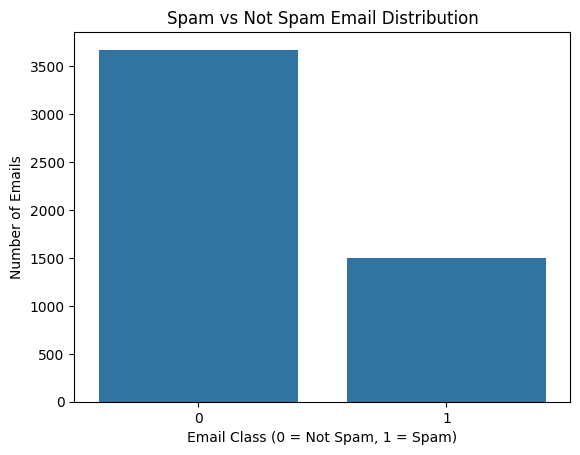

In [6]:
#Class distribution:
sns.countplot(x=y)
plt.title("Spam vs Not Spam Email Distribution")
plt.xlabel("Email Class (0 = Not Spam, 1 = Spam)")
plt.ylabel("Number of Emails")
plt.show()

In [8]:
#Train-test split:
X_train, X_test, y_train, y_test = train_test_split(
 X,
 y,
 test_size=0.2,
 random_state=42,
 stratify=y
)
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 4137
Testing samples: 1035


In [9]:
#Feature Scaling:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Feature scaling completed.")

Feature scaling completed.


In [10]:
#K-Nearest Neighbors Classification
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)
knn_predictions = knn_model.predict(X_test_scaled)
print("KNN classification completed.")

KNN classification completed.


In [11]:
#Support Vector Machine Classification
svm_model = SVC(kernel="linear", C=1.0)
svm_model.fit(X_train_scaled, y_train)
svm_predictions = svm_model.predict(X_test_scaled)
print("SVM classification completed.")

SVM classification completed.


In [12]:
#Model evaluation:
def evaluate_model(y_true, y_pred):
 return {
 "Accuracy": accuracy_score(y_true, y_pred),
 "Precision": precision_score(
 y_true, y_pred, zero_division=0
 ),
 "Recall": recall_score(
 y_true, y_pred, zero_division=0
 ),
 "F1-Score": f1_score(
 y_true, y_pred, zero_division=0
 )
 }
    
knn_results = evaluate_model(y_test, knn_predictions)
svm_results = evaluate_model(y_test, svm_predictions)

results = pd.DataFrame(
 [knn_results, svm_results],
 index=["KNN", "SVM"]
)

display(results.round(4))

,Accuracy,Precision,Recall,F1-Score
KNN,0.8338,0.6435,0.9567,0.7694
SVM,0.9507,0.9136,0.9167,0.9151


In [13]:
#Classification Reports
print("KNN Classification Report:")
print(classification_report(
 y_test,
 knn_predictions,
 target_names=["Not Spam", "Spam"],
 zero_division=0
))
print("\nSVM Classification Report:")
print(classification_report(
 y_test,
 svm_predictions,
 target_names=["Not Spam", "Spam"],
 zero_division=0
))

KNN Classification Report:
              precision    recall  f1-score   support

    Not Spam       0.98      0.78      0.87       735
        Spam       0.64      0.96      0.77       300

    accuracy                           0.83      1035
   macro avg       0.81      0.87      0.82      1035
weighted avg       0.88      0.83      0.84      1035


SVM Classification Report:
              precision    recall  f1-score   support

    Not Spam       0.97      0.96      0.97       735
        Spam       0.91      0.92      0.92       300

    accuracy                           0.95      1035
   macro avg       0.94      0.94      0.94      1035
weighted avg       0.95      0.95      0.95      1035



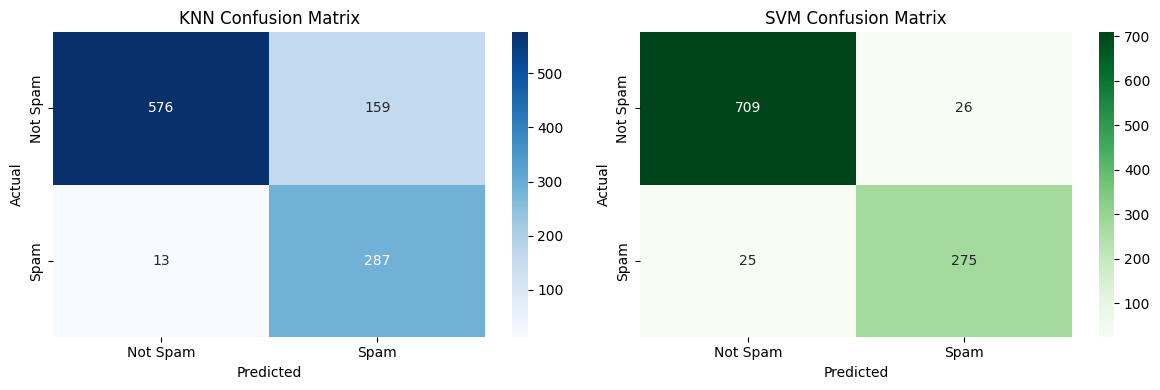

In [14]:
#Confusion Matrix
knn_cm = confusion_matrix(y_test, knn_predictions)
svm_cm = confusion_matrix(y_test, svm_predictions)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(
 knn_cm,
 annot=True,
 fmt="d",
 cmap="Blues",
 xticklabels=["Not Spam", "Spam"],
 yticklabels=["Not Spam", "Spam"],
 ax=axes[0]
)
axes[0].set_title("KNN Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")
sns.heatmap(
 svm_cm,
 annot=True,
 fmt="d",
 cmap="Greens",
 xticklabels=["Not Spam", "Spam"],
 yticklabels=["Not Spam", "Spam"],
 ax=axes[1]
)
axes[1].set_title("SVM Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")
plt.tight_layout()
plt.show()


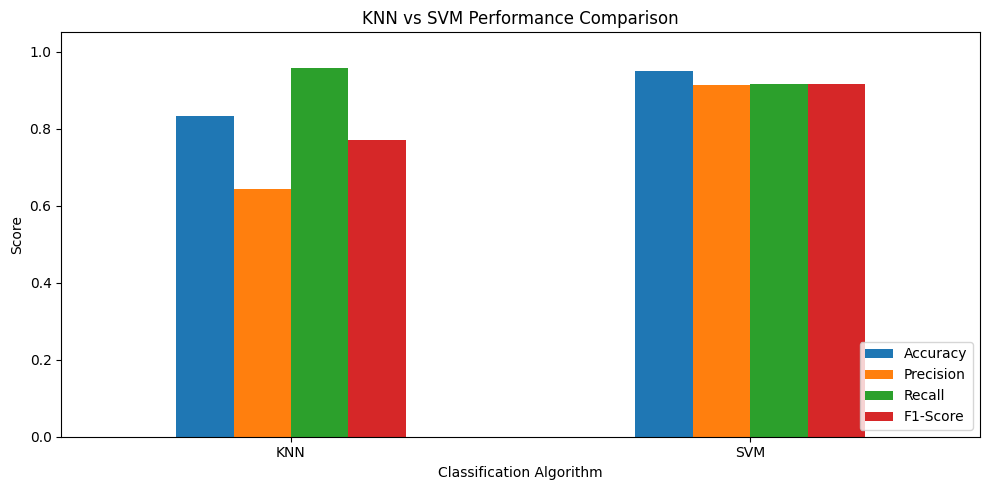

In [15]:
#Performance comparison:
results.plot(kind="bar", figsize=(10, 5))
plt.title("KNN vs SVM Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Classification Algorithm")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [16]:
#Best model:
best_model = results["F1-Score"].idxmax()
print("Best Model based on F1-Score:", best_model)
print("\nPerformance Summary:")
display(results.round(4))

Best Model based on F1-Score: SVM

Performance Summary:


,Accuracy,Precision,Recall,F1-Score
KNN,0.8338,0.6435,0.9567,0.7694
SVM,0.9507,0.9136,0.9167,0.9151
